# **Experimental Demonstration of Quantum Advantage via the Deutsch-Jozsa Algorithm**

# **Aim**:

To study and implement the Deutsch-Jozsa quantum algorithm to distinguish between constant and balanced functions using a single quantum circuit execution, demonstrating a clear query-complexity advantage over classical algorithms.

# Theory:

The Deutsch–Jozsa algorithm determines whether a black-box function (oracle) $f: \{0,1\}^n \rightarrow \{0,1\}$ is constant (returns the same output for all inputs) or balanced (returns 0 for half the inputs and 1 for the other half).

While a classical deterministic algorithm requires up to $2^{n-1} + 1$ queries in the worst case to guarantee an answer, the quantum algorithm evaluates all inputs simultaneously via superposition and requires exactly 1 query.

It relies on phase kickback $(-1)^{f(x)}$ applied through Hadamard gates, causing constructive interference at state $|0\rangle^{\otimes n}$ if $f(x)$ is constant and destructive interference if $f(x)$ is balanced.

# Prerequisites & Package Installation

 Run this cell to install Qiskit, the Aer simulation framework, NumPy and Matplotlib for plotting measurement results.

In [ ]:
# Environment setup and dependencies
!pip install qiskit qiskit-aer matplotlib numpy

# Core module imports
import numpy as np
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator

# **Program Code:**

=== Deutsch-Jozsa Algorithm (3-Qubit Input) ===

--- Constant Oracle ---
Measurement Counts: {'000': 1024}
Evaluated Conclusion: The function is Constant

--- Balanced Oracle ---
Measurement Counts: {'111': 1024}
Evaluated Conclusion: The function is Balanced

Circuit Diagram for Balanced Oracle:
     ┌───┐      ░                 ░ ┌───┐┌─┐      
q_0: ┤ H ├──────░───■─────────────░─┤ H ├┤M├──────
     ├───┤      ░   │             ░ ├───┤└╥┘┌─┐   
q_1: ┤ H ├──────░───┼────■────────░─┤ H ├─╫─┤M├───
     ├───┤      ░   │    │        ░ ├───┤ ║ └╥┘┌─┐
q_2: ┤ H ├──────░───┼────┼────■───░─┤ H ├─╫──╫─┤M├
     ├───┤┌───┐ ░ ┌─┴─┐┌─┴─┐┌─┴─┐ ░ └───┘ ║  ║ └╥┘
q_3: ┤ X ├┤ H ├─░─┤ X ├┤ X ├┤ X ├─░───────╫──╫──╫─
     └───┘└───┘ ░ └───┘└───┘└───┘ ░       ║  ║  ║ 
c: 3/═════════════════════════════════════╩══╩══╩═
                                          0  1  2 


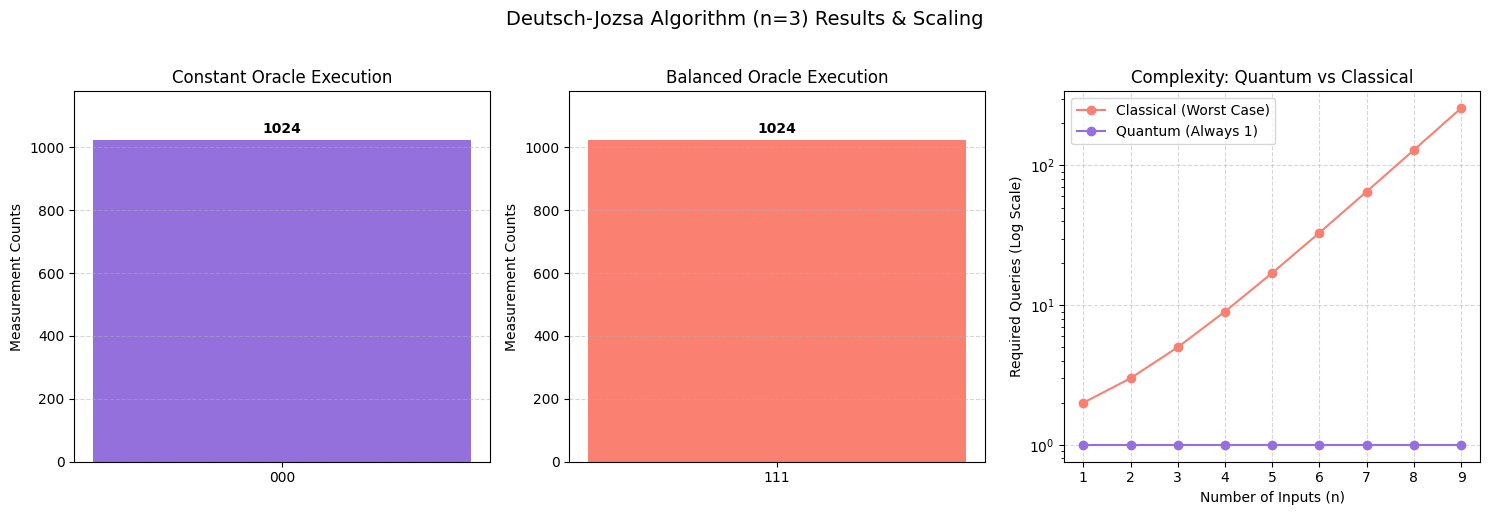

In [8]:
def run_deutsch_jozsa_experiment(n_qubits=3, shots=1024):
    """
    Configures, runs, and visualizes the Deutsch-Jozsa algorithm
    to distinguish between constant and balanced oracles with a single query.
    """
    simulator = AerSimulator()

    # 1. Helper function to construct Constant or Balanced Oracles
    def build_oracle(case, n):
        oracle = QuantumCircuit(n + 1)
        if case == "constant":
            # Randomly output either all 0s or all 1s
            if np.random.randint(2) == 1:
                oracle.x(n)
        elif case == "balanced":
            # CNOT gates from each input qubit to the target qubit create a balanced function
            for q in range(n):
                oracle.cx(q, n)
        return oracle

    # 2. Deutsch-Jozsa Quantum Circuit Generator
    def dj_circuit(oracle, n):
        qc = QuantumCircuit(n + 1, n)

        # Initialize the target qubit (ancilla) in state |1>
        qc.x(n)

        # Apply Hadamard gates to put all qubits in superposition
        qc.h(range(n + 1))
        qc.barrier()

        # Apply the black-box oracle (triggers phase kickback)
        qc.compose(oracle, inplace=True)
        qc.barrier()

        # Apply Hadamard gates to the input qubits to interfere amplitudes
        qc.h(range(n))

        # Measure input register
        qc.measure(range(n), range(n))
        return qc

    results = {}
    circuits = {}

    print(f"=== Deutsch-Jozsa Algorithm ({n_qubits}-Qubit Input) ===\n")

    for case in ["constant", "balanced"]:
        oracle = build_oracle(case, n_qubits)
        qc = dj_circuit(oracle, n_qubits)
        circuits[case] = qc

        # Transpiling and executing the simulation
        transpiled_qc = transpile(qc, simulator)
        counts = simulator.run(transpiled_qc, shots=shots).result().get_counts()
        results[case] = counts

        # A result of all '0's indicates a constant function, anything else indicates balanced
        measured_state = list(counts.keys())[0]
        detected = "Constant" if measured_state == "0" * n_qubits else "Balanced"

        print(f"--- {case.capitalize()} Oracle ---")
        print(f"Measurement Counts: {counts}")
        print(f"Evaluated Conclusion: The function is {detected}\n")

    print("Circuit Diagram for Balanced Oracle:")
    print(circuits["balanced"].draw('text'))

    # 3. VISUALIZATION
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))

    # Subplot 1: Constant Oracle Result
    counts_c = results["constant"]
    axes[0].bar(counts_c.keys(), counts_c.values(), color='mediumpurple', width=0.4)
    axes[0].set_title("Constant Oracle Execution")
    axes[0].set_ylabel("Measurement Counts")
    axes[0].set_ylim(0, shots * 1.15)
    for k, v in counts_c.items():
        axes[0].text(k, v + 20, str(v), ha='center', fontweight='bold')
    axes[0].grid(axis='y', ls='--', alpha=0.5)

    # Subplot 2: Balanced Oracle Result
    counts_b = results["balanced"]
    axes[1].bar(counts_b.keys(), counts_b.values(), color='salmon', width=0.4)
    axes[1].set_title("Balanced Oracle Execution")
    axes[1].set_ylabel("Measurement Counts")
    axes[1].set_ylim(0, shots * 1.15)
    for k, v in counts_b.items():
        axes[1].text(k, v + 20, str(v), ha='center', fontweight='bold')
    axes[1].grid(axis='y', ls='--', alpha=0.5)

    # Subplot 3: Query Complexity Comparison
    n_range = np.arange(1, 10)
    axes[2].plot(n_range, 2**(n_range - 1) + 1, 'o-', color='salmon', label='Classical (Worst Case)')
    axes[2].plot(n_range, np.ones_like(n_range), 'o-', color='mediumpurple', label='Quantum (Always 1)')
    axes[2].set_title("Complexity: Quantum vs Classical")
    axes[2].set_xlabel("Number of Inputs (n)")
    axes[2].set_ylabel("Required Queries (Log Scale)")
    axes[2].set_yscale('log')
    axes[2].legend()
    axes[2].grid(True, ls='--', alpha=0.5)

    plt.suptitle(f"Deutsch-Jozsa Algorithm (n={n_qubits}) Results & Scaling", fontsize=14, y=1.02)
    plt.tight_layout()
    plt.show()

# Run the optimized experiment
run_deutsch_jozsa_experiment(n_qubits=3)

### 📊 Experimental Results

The plots above present the empirical verification of the Deutsch-Jozsa algorithm sampled over **1,024 shots** on the `AerSimulator`:

* **Constant Oracle Execution (Left)**: Shows 100% of the measurement counts at the state $|000\rangle$, correctly demonstrating that the oracle function is constant.
* **Balanced Oracle Execution (Middle)**: Shows 100% of the measurement counts at a non-zero state ($|111\rangle$), correctly identifying that the oracle function is balanced.
* **Complexity Comparison (Right)**: Shows the query scaling for classical algorithms ($2^{n-1} + 1$) versus the quantum algorithm which remains constant at $1$ query regardless of the input dimension $n$.

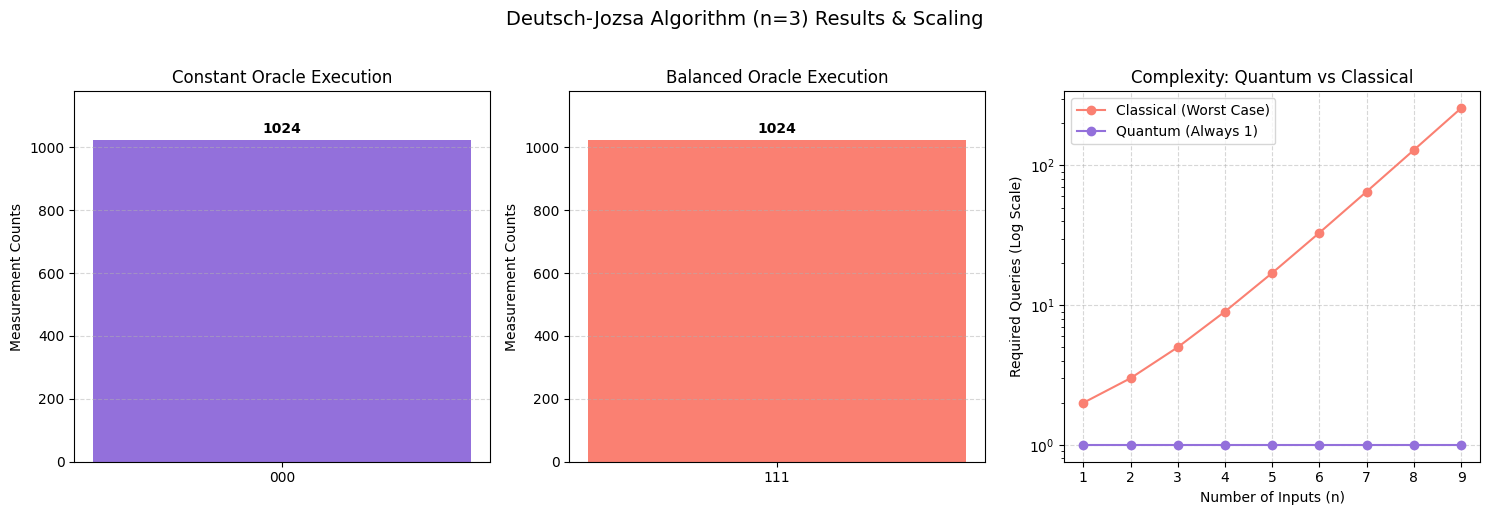

# **Observation**:

The Deutsch-Jozsa algorithm successfully distinguishes between constant and balanced functions in a single query with 100% accuracy, verifying quantum query speedup over classical algorithms.